In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score


In [4]:
print("First 5 rows of the dataset:")
print(df.head())
print("\nDataset information:")
print(df.info())

First 5 rows of the dataset:
   PRN           DO             PD         RX            TOW            CP  \
0    6  1160.671408 -238359.543282  491568.00  491568.000795 -24660.263293   
1    6  1157.827808 -238363.921192  491568.02  491568.020795 -24683.468520   
2    6  1161.135932 -238368.638615  491568.04  491568.040795 -24706.687357   
3    6  1161.156617 -238373.391775  491568.06  491568.060795 -24729.920039   
4    6  1160.690893 -238378.127066  491568.08  491568.080795 -24753.153999   

          EC         LC         PC        PIP          PQP        TCD  \
0  163521.78  170008.81  179294.97  178420.33 -17688.17800  1158.4806   
1  158277.05  160253.09  182106.11  182106.05    158.33333  1160.7948   
2  184442.36  193125.89  208228.02 -205198.30  35391.59000  1157.6909   
3  159812.45  169960.55  187550.72  187543.00  -1701.94400  1161.1343   
4  183557.66  191912.58  208403.50  208330.05  -5532.89990  1161.1759   

         CN0  Output  
0  49.412529       0  
1  49.452686     

In [ ]:
from gps_ids import protocol, training

EXP = protocol.real_heldout("2d")
r = training.run("XGBoost", EXP)
model = r.model
y_pred = r.y_pred
y_test = EXP.y_test
feature_names = EXP.feature_names


In [7]:
# Report the model's performance on the test set
print("\nEvaluating the model on the test set...")
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"Model Accuracy on Test Set: {accuracy * 100:.2f}%")
print(f"F1 Score: {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Evaluating the model on the test set...
Model Accuracy on Test Set: 13.15%
F1 Score: 0.1290

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.09      0.15    318260
           1       0.00      0.00      0.00     29166
           2       0.15      0.00      0.00     35386
           3       0.07      1.00      0.13     25612

    accuracy                           0.13    408424
   macro avg       0.21      0.27      0.07    408424
weighted avg       0.51      0.13      0.13    408424



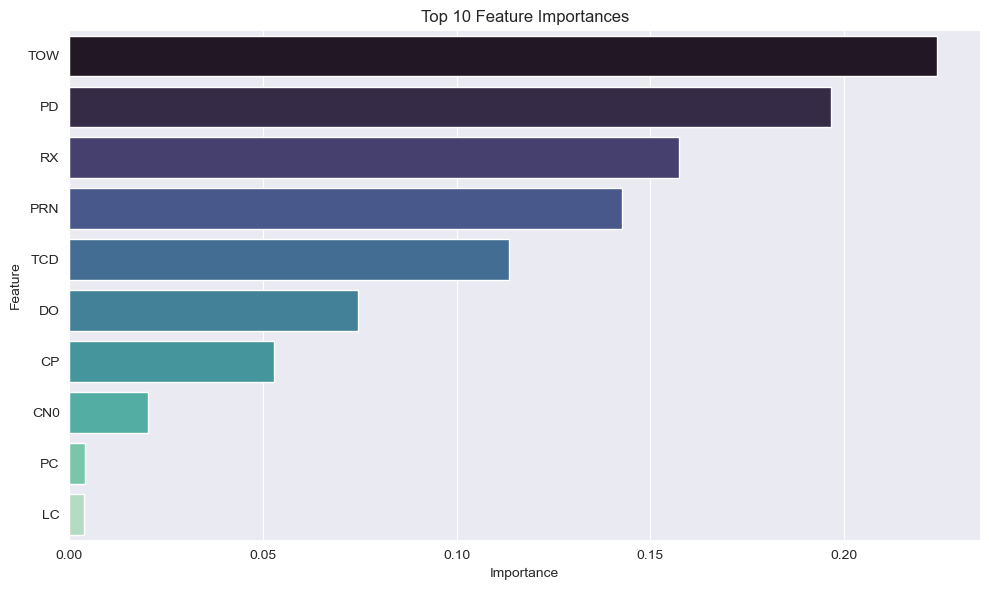

In [9]:
importances = model.feature_importances_

# Create a DataFrame for feature importances
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort by importance descending
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=feat_imp_df.head(10),
    x='Importance',
    y='Feature',
    palette='mako',
    hue='Feature',
    legend=False
)
plt.title('Top 10 Feature Importances')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=800)
plt.show()

In [10]:
print(feat_imp_df.head(10))

   Feature  Importance
4      TOW    0.223913
2       PD    0.196729
3       RX    0.157455
0      PRN    0.142636
11     TCD    0.113491
1       DO    0.074641
5       CP    0.052822
12     CN0    0.020185
8       PC    0.004042
7       LC    0.003671
